In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from pathlib import Path
import joblib
import seaborn as sns
from unicodedata import category
from fontTools.diff import color

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

In [2]:
data = pd.read_csv('../data/housing_az_sqm_azn.csv')

In [3]:
data.head()

,PriceAZN,Bedrooms,Bathrooms,Sqm,City
0,225000,1,1,87.9,Baku
1,53200,3,2,45.0,Sumqayit
2,224100,3,2,81.2,Baku
3,318500,4,1,120.6,Baku
4,148900,5,1,126.9,Ganja


In [4]:
data.shape

(240, 5)

In [5]:
data.describe()

,PriceAZN,Bedrooms,Bathrooms,Sqm
count,240.000000,240.000000,240.00000,240.000000
mean,147927.083333,2.908333,2.01250,92.547917
std,71134.645560,1.420094,0.82066,27.146753
min,40000.000000,1.000000,1.00000,45.000000
25%,94400.000000,2.000000,1.00000,72.200000
50%,126950.000000,3.000000,2.00000,92.750000
75%,192525.000000,4.000000,3.00000,110.700000
max,401100.000000,5.000000,3.00000,171.100000


In [6]:
data.dtypes

PriceAZN       int64
Bedrooms       int64
Bathrooms      int64
Sqm          float64
City             str
dtype: object

In [7]:
data.isna().sum()

PriceAZN     0
Bedrooms     0
Bathrooms    0
Sqm          0
City         0
dtype: int64

In [9]:
y = data['PriceAZN'].astype(float)
X = data.drop('PriceAZN', axis=1)

[]

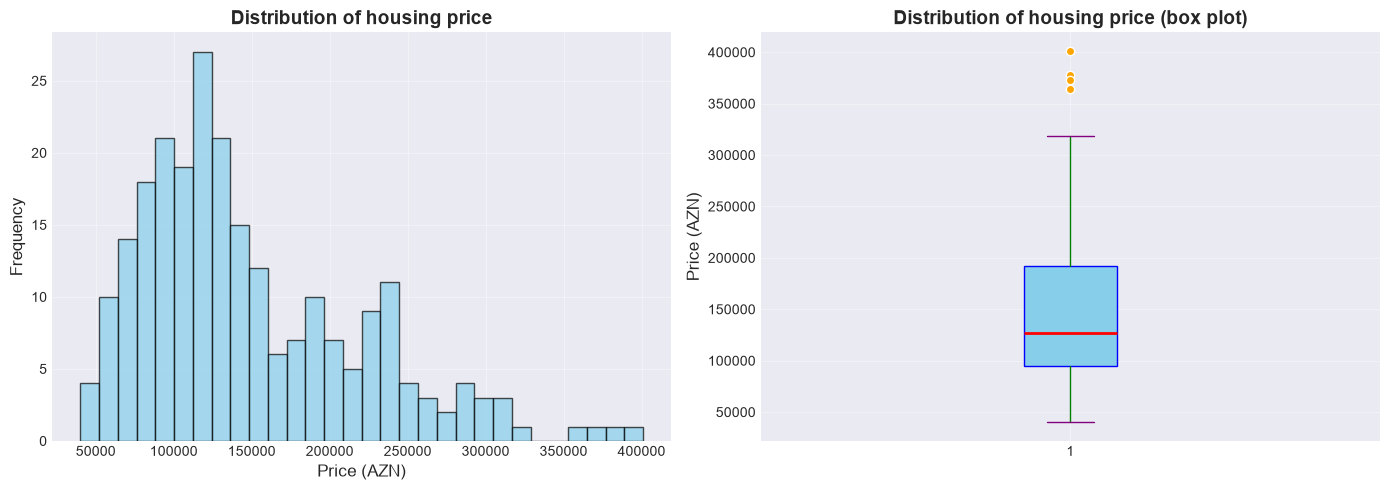

In [13]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

axes[0].hist(y, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of housing price', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Price (AZN)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].grid(True, alpha=0.5)

axes[1].boxplot(
    y,
    orientation='vertical',
    patch_artist=True,
    boxprops=dict(facecolor='skyblue', color='blue'),
    medianprops=dict(color='red', linewidth=2),
    whiskerprops=dict(color='green'),
    capprops=dict(color='purple'),
    flierprops=dict(markerfacecolor='orange', marker='o')
)
axes[1].set_title('Distribution of housing price (box plot)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Price (AZN)', fontsize=12)
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.plot()

In [14]:
print(f"""
Price statistics:
Mean: {y.mean():.2f} AZN
Median: {y.median():.2f} AZN
Min: {y.min():.2f} AZN
Max: {y.max():.2f} AZN
Std. dev: {y.std():.2f} AZN
""")


Price statistics:
Mean: 147927.08 AZN
Median: 126950.00 AZN
Min: 40000.00 AZN
Max: 401100.00 AZN
Std. dev: 71134.65 AZN



In [15]:
numeric_features = ['Bedrooms', 'Bathrooms', 'Sqm']
categorical_features = ['City']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [17]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)

In [18]:
pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', rf)
])

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
len(X_train), len(X_test)

(192, 48)

In [20]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Bedrooms','Bathrooms','Sqm','City']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of t

In [21]:
pred = pipe.predict(X_test)

mae = mean_absolute_error(y_test, pred)
mse = mean_squared_error(y_test, pred)
rmse = root_mean_squared_error(y_test, pred)
r2 = r2_score(y_test, pred)

print(f"""
Model Metrics:
MAE: {mae:.2f}
MSE: {mse:.2f}
RMSE: {rmse:.2f}
R2: {r2:.2f}
""")


Model Metrics:
MAE: 15489.78
MSE: 447058167.30
RMSE: 21143.75
R2: 0.89



In [27]:
test_predictions = pd.DataFrame({
    'Bedrooms': [3],
    'Bathrooms': [2],
    'Sqm': [40],
    'City': ['Ganja'],
})

prediction = pipe.predict(test_predictions)[0]
print(f"Predicted Price: {prediction:.2f}")


Predicted Price: 59555.33


In [28]:
bundle = {
    'pipeline': pipe,
    'featured_order': ['Bedrooms', 'Bathrooms', 'Sqm', 'City'],
}

model_path = Path('../models/model.pkl')

joblib.dump(bundle, model_path)

['..\\models\\model.pkl']